### Dimensionality Reduction in python (Curse of dimensionality)

Nowadays, many ML probelms involve thousands or even million of features for each instance. Although this help the models to learn usefull patterns and extract useful insights from data, it makes the training extremely slow and much harder to find a good solution. The goal of this notebbok is to explore different methods for dimensionality reduction.

For this work, we will use BreastMNIST, a data set from MedMNISt that contains breast ultrasound. We will explore dimensionality reduction on it and train a classification model on it to identify which one are malign. After that, we will train a direct CNN model on the original dataset to analyse the different results.

In [1]:
! pip install medmnist --quiet


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from medmnist import BreastMNIST

# For a beginning, we will use only the train data to apply dimension reduction
train_dataset = BreastMNIST(split="train", download = True, size = 224)

Using downloaded and verified file: C:\Users\pavel\.medmnist\breastmnist_224.npz


In [3]:
len(train_dataset)

546

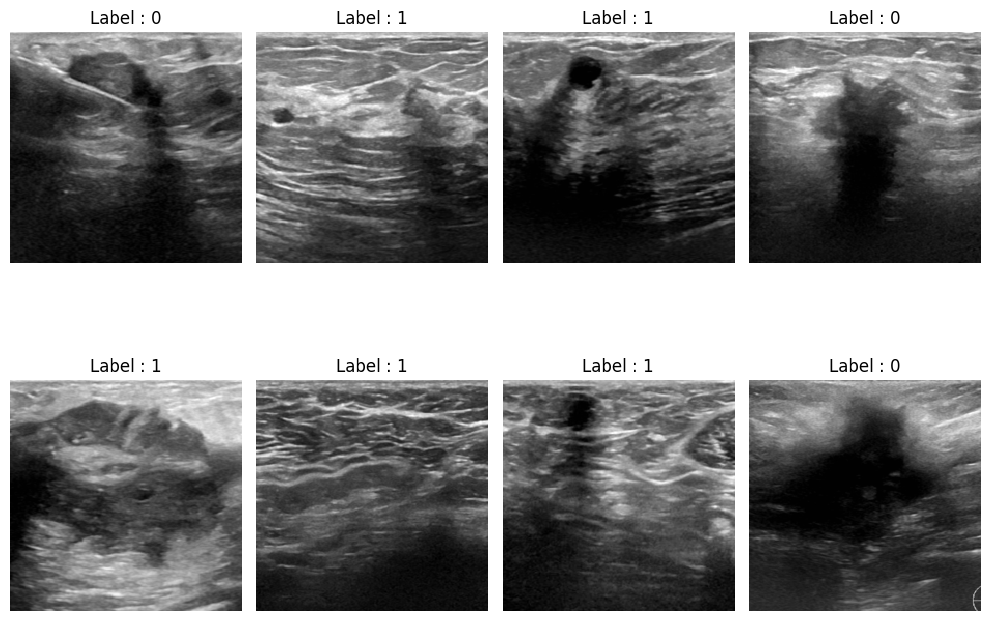

In [4]:
# visualization
import random
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 4, figsize=(10, 8))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[random.randint(0,546)]

    ax.imshow(image, cmap="gray", interpolation="nearest")
    ax.set_title(f"Label : {label[0]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Here, the dimension of the image is 224x224 = 50176. If you want to train a MLP on this, you will need 50176 in the first layer and this is to much. The training will be low. Another alternative exists. It's to use Convolutional Neural Network but as the goal of this notebook is to mainly explore dimensionality reduction, let's pursue it. The goal will be to reduce the dimension in other to train an MLP on this dataset to compare the accuracy it will provide with the accuracy using CNN.

In [27]:
import numpy as np

def to_numpy(dataset):

    num_data = len(dataset)

    train_data = np.zeros((num_data, 224, 224))
    labels = np.zeros(num_data)

    for i in range(num_data):
        image, label = dataset[i]

        train_data[i] = np.array(image)
        labels[i] = label[0]
    
    return train_data, labels

train_data, labels = to_numpy(train_dataset)
print(train_data.shape)
print(labels.shape)

(546, 224, 224)
(546,)


### PCA (principal component analysis)
Project the data on the hyperplane that is closed to them and that preserved the maximum amount of variance (information). ANother way to say it, is the hyperplane that minimizes the distance(mean squared distance) between the original dataset and its projection onto the axis. To project your data in a d dimensional space, you take the d first principal component an then do a matrice multiplication between the matrice formed with the d first principal component and the dataset. To obtain the first d prinicpal component, you do a SVD of your data (that is to write $X = W\sum V^T $) and then take the d first vectors in V. 
Let's use PCA in practice and apply it to te BreastMNIST


In [6]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import time

In [7]:
train_data_reshaped = train_data.reshape(num_data, 224*224)
train_data_reshaped.shape

(546, 50176)

In [8]:
start_time = time.time()

pca = PCA()
data_256D = pca.fit_transform(train_data_reshaped)

end_time = time.time()

elapsed_time = end_time-start_time
print(f"The execution took {elapsed_time} seconds ")
print(f"The new shape is {data_256D.shape}")

The execution took 5.172231912612915 seconds 
The new shape is (546, 546)


Wow, that was too fast. Now, let's check the amount of information that was captured in the data by checking the variance ration

In [9]:
pca.explained_variance_ratio_

array([2.56274756e-01, 1.24546498e-01, 5.98663820e-02, 5.26828230e-02,
       3.61819684e-02, 2.90250985e-02, 2.51204911e-02, 1.77544288e-02,
       1.53923562e-02, 1.29712630e-02, 1.20670677e-02, 1.01482279e-02,
       9.14716201e-03, 8.34494295e-03, 7.44002460e-03, 7.14907384e-03,
       6.59697833e-03, 6.10586214e-03, 5.35475574e-03, 5.28878105e-03,
       4.98673402e-03, 4.46688782e-03, 4.32524647e-03, 4.13116975e-03,
       4.09290472e-03, 3.85879134e-03, 3.71444610e-03, 3.53099882e-03,
       3.44222197e-03, 3.38118711e-03, 3.15882279e-03, 3.09746456e-03,
       2.96340045e-03, 2.95301284e-03, 2.83864925e-03, 2.79896494e-03,
       2.69556719e-03, 2.64134246e-03, 2.59586422e-03, 2.55228333e-03,
       2.48352137e-03, 2.46571744e-03, 2.36842892e-03, 2.24541308e-03,
       2.20314065e-03, 2.16273033e-03, 2.12216096e-03, 2.10029276e-03,
       2.05478462e-03, 1.97043429e-03, 1.91456838e-03, 1.86391956e-03,
       1.82205701e-03, 1.78865220e-03, 1.75714479e-03, 1.70371762e-03,
      

This shows us the variance percentage of the dataset lieas along each axis. We can see that the the first axis have 25% of the total variance, wich is not that small but to increase it, we can increase the number of components. But instead of choosing the number of dimension arbitrarily, it is generally preferable to choose the number of dimensions that add up to a sufficiently large portion of the variance(example 85%). Unless of course you are reducing the number of dimensionality for data vizualization in that case, you will generally want to reduce the dimensionality down to 2 or 3. The following code computes the minimum number of the dimensions required to preserve 85% of the training set's variance.

In [19]:
cumsum = np.cumsum(pca.explained_variance_ratio_)
d = np.argmax(cumsum >= 0.85) +1
print(f"The number of required components to get explained variance of 80% is {d}")

The number of required components to get explained variance of 80% is 87


In [21]:
d_80 = np.argmax(cumsum >= 0.80) + 1
d_90 = np.argmax(cumsum >= 0.90) + 1
d_95 = np.argmax(cumsum >= 0.95) + 1

print("Required components for 80% :", d_80)
print("Required components for 90% :", d_90)
print("Required components for 95% :", d_95)

Required components for 80% : 52
Required components for 90% : 145
Required components for 95% : 251


One problem with PCA is that it doesn't know the labels. A small part of the variance that we delete could eventually contain some important characteristics for the classification. That is why we can use these dimension to train our MLP and then choose the one with the highest accuracy on validation data. 

Now I am going to train a MLP from scratch on the projected data to predict whether a picture is a malignant breast cancer or a benign one. I will use only the reduced one with 87 coordinates (85% of the variance)

As we are going to train a neural nework from scratch using pytorch, I need to use tensors in what follows 

In [23]:
import torch
import torch.nn as nn

In [39]:
print("Loading ...")
# Let's read the data
train_dataset = BreastMNIST(split="train", size=224) # I redid it on purpose
valid_dataset = BreastMNIST(split="val", size=224)
test_dataset = BreastMNIST(split="test",  size = 224)

#Let's transform them into numpy
train_dataset, train_labels = to_numpy(train_dataset)
test_dataset, test_labels = to_numpy(test_dataset)
valid_dataset, valid_labels = to_numpy(valid_dataset)

#Let's reshape them
train_dataset_reshaped = train_dataset.reshape(-1, 224*224)
test_dataset_reshaped = test_dataset.reshape(-1, 224*224)
valid_dataset_reshaped = valid_dataset.reshape(-1, 224*224)

#Let's fit them with pca according to what we did before
pca2 = PCA(n_components=0.85, svd_solver="full")
X_train = pca2.fit_transform(train_data_reshaped)
X_test = pca2.transform(test_dataset_reshaped) # Notice the absence of fit here, as we have fit on the data, we apply the same transformation on test and valid data
X_valid = pca2.transform(valid_dataset_reshaped)

#Let's transform them into tensor
X_train, y_train = torch.tensor(X_train, dtype=torch.float32), torch.tensor(train_labels, dtype=torch.long).squeeze()
X_test, y_test = torch.tensor(X_test, dtype=torch.float32), torch.tensor(test_labels, dtype=torch.long).squeeze()
X_valid, y_valid = torch.tensor(X_valid, dtype=torch.float32), torch.tensor(valid_labels, dtype=torch.long).squeeze()

print("The pretreatment is finished")
print("Train:", X_train.shape, y_train.shape)
print("Valid:", X_valid.shape, y_valid.shape)
print("Test :", X_test.shape, y_test.shape)

Loading ...
The pretreatment is finished
Train: torch.Size([546, 87]) torch.Size([546])
Valid: torch.Size([78, 87]) torch.Size([78])
Test : torch.Size([156, 87]) torch.Size([156])


To be continued.